# Site figures

Drawn from `results/phase2_modelclass_results.csv`. Presentation only.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "figures" / "site"
OUT.mkdir(parents=True, exist_ok=True)

BLUE, RED, GREY, LIGHT = "#2166ac", "#b2182b", "#8c8c8c", "#d9d9d9"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#eeeeee",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 100,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def titled(ax, title, sub=None):
    ax.set_title(title, pad=24 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=10, color="#555555", va="bottom")


def save(fig, name):
    fig.savefig(OUT / name, facecolor="white")
    plt.show()


## Every model class against a univariate AR

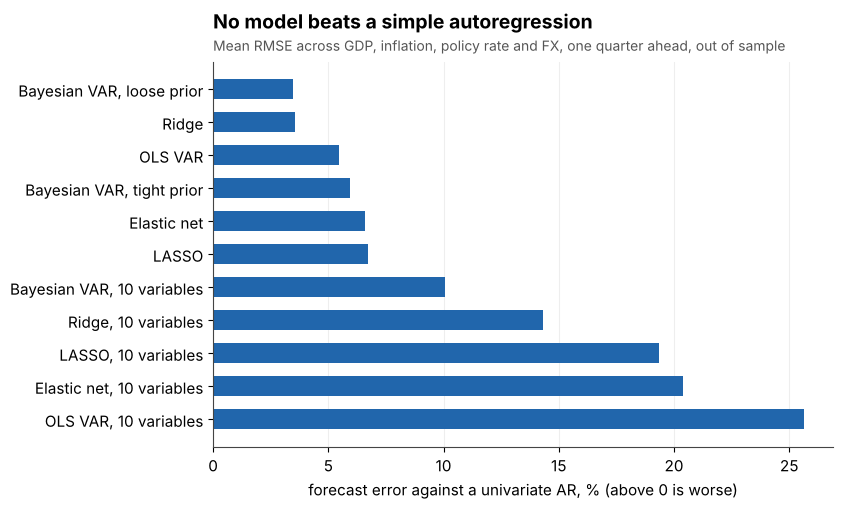

In [2]:
p = pd.read_csv(ROOT / "results/phase2_modelclass_results.csv").set_index("model_id")
ar = p.loc["AR(BIC)", "mean_relRMSE_h1"]
rel = (p.mean_relRMSE_h1 / ar).drop(["AR(BIC)", "RW"]).sort_values()
NAMES = {"BVAR-Loose:small": "Bayesian VAR, loose prior", "Ridge:small": "Ridge", "OLS:small": "OLS VAR",
         "BVAR-Tight:small": "Bayesian VAR, tight prior", "ENet:small": "Elastic net", "LASSO:small": "LASSO",
         "BVAR-Tight:wide": "Bayesian VAR, 10 variables", "Ridge:wide": "Ridge, 10 variables",
         "LASSO:wide": "LASSO, 10 variables", "ENet:wide": "Elastic net, 10 variables", "OLS:wide(overfit)": "OLS VAR, 10 variables"}
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([NAMES.get(m, m) for m in rel.index][::-1], (rel.values[::-1] - 1) * 100, color=BLUE, height=0.6)
ax.axvline(0, color=RED, lw=1.2)
ax.set_xlabel("forecast error against a univariate AR, % (above 0 is worse)")
ax.grid(axis="y", visible=False)
titled(ax, "No model beats a simple autoregression",
       "Mean RMSE across GDP, inflation, policy rate and FX, one quarter ahead, out of sample")
save(fig, "models_vs_ar.png")